# Project 5 - Data analysis

In [1]:
import glob
import os
import pandas as pd
import matplotlib.pyplot as plt

PART1_RESULTS = "../part1/results"
PART2_RESULTS = "../part2/results"
FIGURE_FOLDER = "../submission/report"   # the plots are saved here for the report

# Colors and style
BLUE = "#2a78d6"
TEXT = "#0b0b0b"
TEXT_LIGHT = "#52514e"
GRID = "#e4e3df"
BACKGROUND = "#fcfcfb"

plt.rcParams.update({
    "font.size": 10,
    "axes.edgecolor": TEXT_LIGHT,
    "axes.labelcolor": TEXT,
    "xtick.color": TEXT_LIGHT,
    "ytick.color": TEXT_LIGHT,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": BACKGROUND,
    "axes.facecolor": BACKGROUND,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
})

## Part 1: Response time

Min, median, mean, 99 % and max delay for every test, in microseconds.

In [2]:
part1_rows = []

for file_name in sorted(glob.glob(f"{PART1_RESULTS}/delays_*.txt")):
    test_name = os.path.basename(file_name)[len("delays_"):-len(".txt")]
    delays_us = pd.read_csv(file_name, header=None)[0]

    part1_rows.append({
        "test": test_name,
        "n": len(delays_us),
        "min": delays_us.min(),
        "median": delays_us.median(),
        "mean": delays_us.mean(),
        "99 %": delays_us.quantile(0.99),
        "max": delays_us.max(),
    })

part1_table = pd.DataFrame(part1_rows).set_index("test").round(1)
part1_table

,n,min,median,mean,99 %,max
test,,,,,,
events_idle,1000,55.5,65.3,65.9,99.0,147.5
events_load,1000,37.3,91.0,121.4,279.2,5825.3
events_load_rt,1000,32.8,82.2,76.8,134.3,189.9
lkm_idle,1000,5.4,9.5,9.3,24.6,49.2
lkm_load,1000,5.6,13.0,16.8,38.3,66.5
poll_idle,1000,9.6,105.3,91.9,181.7,185.9
poll_load,1000,9.7,113.6,105.8,184.4,2121.6
poll_load_rt,1000,10.2,74.5,72.8,131.8,141.7
shell_idle,200,5966.9,11254.6,10935.4,14236.8,14277.4


## Part 2: Load the control loop logs

In [3]:
part2_runs = {
    "Normal": "log_normal.csv",
    "CPU fully loaded": "log_load.csv",
    "Loaded + SCHED_FIFO 80": "log_load_rt.csv",
}

part2_logs = {}
for run_name, file_name in part2_runs.items():
    log = pd.read_csv(f"{PART2_RESULTS}/{file_name}")
    log["loop_time_ms"] = log["loop_time_us"] / 1000
    log["time_s"] = log["loop_time_ms"].cumsum() / 1000
    part2_logs[run_name] = log

## Part 2: Loop time and speed statistics

Loop times in ms. Speed and duty after the first quarter of the run (start-up left out).

In [4]:
part2_rows = []

for run_name, log in part2_logs.items():
    loop_ms = log["loop_time_ms"]
    after_startup = log.iloc[len(log) // 4:]

    part2_rows.append({
        "run": run_name,
        "loops": len(log),
        "min": loop_ms.min(),
        "median": loop_ms.median(),
        "mean": loop_ms.mean(),
        "99 %": loop_ms.quantile(0.99),
        "max": loop_ms.max(),
        "std": loop_ms.std(),
        "loops > 5 ms": (loop_ms > 5).sum(),
        "speed mean": after_startup["speed_rpm"].mean(),
        "speed std": after_startup["speed_rpm"].std(),
        "duty mean": after_startup["duty_percent"].mean(),
    })

part2_table = pd.DataFrame(part2_rows).set_index("run").round(3)
part2_table

,loops,min,median,mean,99 %,max,std,loops > 5 ms,speed mean,speed std,duty mean
run,,,,,,,,,,,
Normal,2453,4.013,4.074,4.077,4.154,4.236,0.015,0,50.008,4.523,44.707
CPU fully loaded,2381,3.981,4.051,4.201,7.138,8.081,0.551,98,49.989,4.765,44.778
Loaded + SCHED_FIFO 80,2466,3.946,4.058,4.056,4.205,4.286,0.072,0,49.999,4.660,45.754


## Figure 1: Loop time histogram

Control loop time for the three runs. Log scale on the count. Dashed line = the 3.9 ms we ask for.

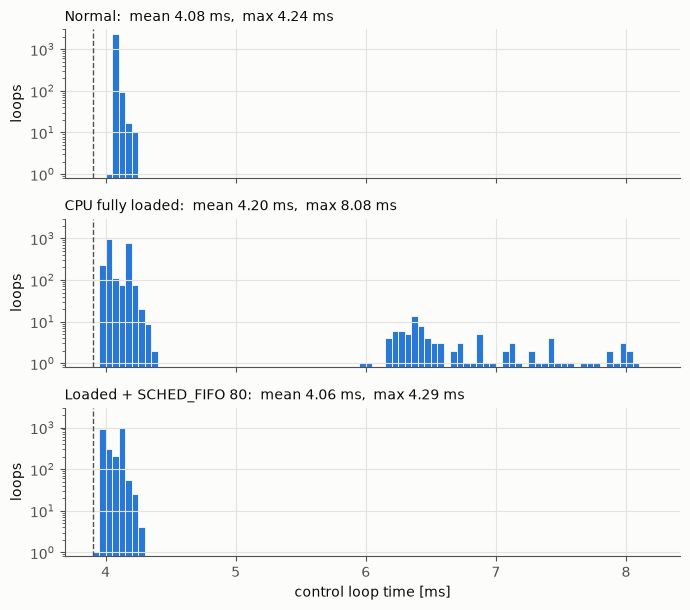

In [5]:
bins = [3.9 + 0.05 * i for i in range(87)]

figure, axes = plt.subplots(3, 1, figsize=(7, 6.2), sharex=True)

for axis, (run_name, log) in zip(axes, part2_logs.items()):
    loop_ms = log["loop_time_ms"]
    axis.hist(loop_ms, bins=bins, color=BLUE, edgecolor=BACKGROUND, linewidth=0.6)
    axis.set_yscale("log")
    axis.set_ylim(0.8, 3000)
    axis.axvline(3.9, color=TEXT_LIGHT, linestyle="--", linewidth=1)
    axis.set_ylabel("loops")
    axis.set_title(f"{run_name}:  mean {loop_ms.mean():.2f} ms,  max {loop_ms.max():.2f} ms",
                   loc="left", fontsize=10, color=TEXT)

axes[-1].set_xlabel("control loop time [ms]")
figure.tight_layout()
figure.savefig(f"{FIGURE_FOLDER}/part2_loop_time_histogram.png", dpi=150)
plt.show()

## Figure 2: Speed and duty, normal run

10 s at 50 rpm.

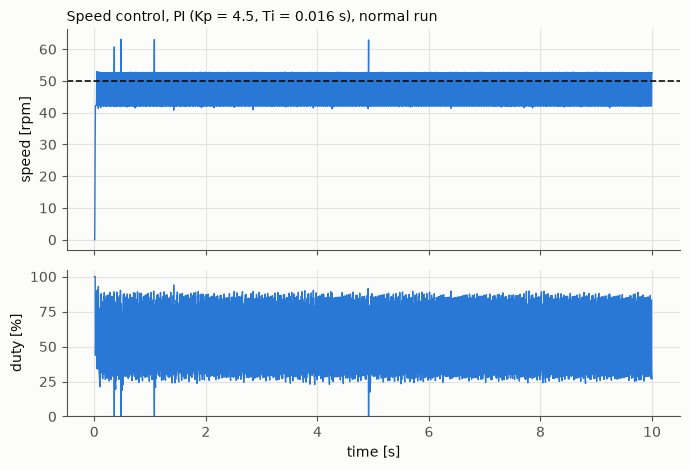

In [6]:
log = part2_logs["Normal"]

figure, (speed_axis, duty_axis) = plt.subplots(2, 1, figsize=(7, 4.8), sharex=True,
                                               gridspec_kw={"height_ratios": [3, 2]})

speed_axis.plot(log["time_s"], log["speed_rpm"], color=BLUE, linewidth=1)
speed_axis.axhline(50, color=TEXT, linestyle="--", linewidth=1.2)
speed_axis.set_ylabel("speed [rpm]")
speed_axis.set_title("Speed control, PI (Kp = 4.5, Ti = 0.016 s), normal run",
                     loc="left", fontsize=10, color=TEXT)

duty_axis.plot(log["time_s"], log["duty_percent"], color=BLUE, linewidth=1)
duty_axis.set_ylabel("duty [%]")
duty_axis.set_xlabel("time [s]")
duty_axis.set_ylim(0, 105)

figure.tight_layout()
figure.savefig(f"{FIGURE_FOLDER}/part2_speed_normal.png", dpi=150)
plt.show()

## Figure 3: Start-up, first 0.5 s

One dot = one control loop.

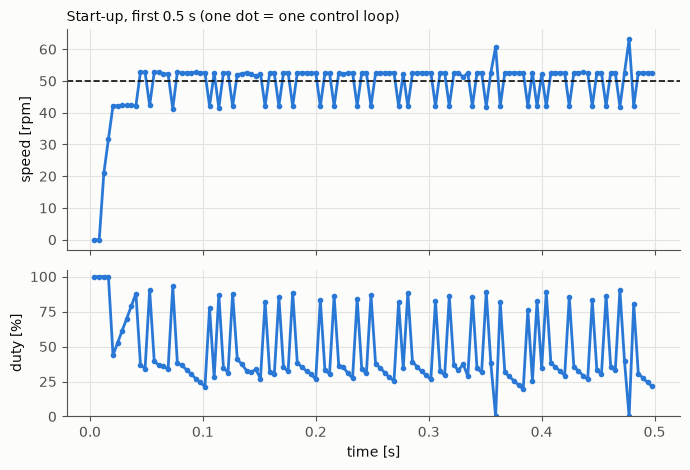

In [7]:
start_up = part2_logs["Normal"]
start_up = start_up[start_up["time_s"] < 0.5]

figure, (speed_axis, duty_axis) = plt.subplots(2, 1, figsize=(7, 4.8), sharex=True,
                                               gridspec_kw={"height_ratios": [3, 2]})

speed_axis.plot(start_up["time_s"], start_up["speed_rpm"], color=BLUE, linewidth=2, marker="o", markersize=3)
speed_axis.axhline(50, color=TEXT, linestyle="--", linewidth=1.2)
speed_axis.set_ylabel("speed [rpm]")
speed_axis.set_title("Start-up, first 0.5 s (one dot = one control loop)",
                     loc="left", fontsize=10, color=TEXT)

duty_axis.plot(start_up["time_s"], start_up["duty_percent"], color=BLUE, linewidth=2, marker="o", markersize=3)
duty_axis.set_ylabel("duty [%]")
duty_axis.set_xlabel("time [s]")
duty_axis.set_ylim(0, 105)

figure.tight_layout()
figure.savefig(f"{FIGURE_FOLDER}/part2_speed_startup.png", dpi=150)
plt.show()